# Bab 1 — Exploratory Data Analysis

**Rujukan:** Bruce, Bruce & Gedeck, *Practical Statistics for Data Scientists*, edisi 2, Bab 1. Notebook ini menulis ulang contoh inti dengan penjelasan dan kode orisinal, bukan salinan kode buku. Dataset `state.csv` berasal dari repositori pendamping resmi.

**Tujuan:** membedakan tipe data, menghitung ukuran pusat/sebaran, membaca distribusi dan hubungan antarvariabel, lalu menjelaskan mengapa ringkasan numerik saja tidak cukup. Jalankan dari root repositori atau melalui notebook ini (path dicari otomatis).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
state = pd.read_csv(ROOT / 'data' / 'state.csv')
state.head()

mkdir -p failed for path C:\Users\Rangga Timotius\AppData\Local\matplotlib: [WinError 5] Access is denied: 'C:\\Users\\Rangga Timotius\\AppData\\Local\\matplotlib'


Matplotlib created a temporary cache directory at C:\Users\RANGGA~1\AppData\Local\Temp\matplotlib-gbkzce4t because there was an issue with the default path (C:\Users\Rangga Timotius\AppData\Local\matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


,State,Population,Murder.Rate,Abbreviation
0,Alabama,4779736,5.7,AL
1,Alaska,710231,5.6,AK
2,Arizona,6392017,4.7,AZ
3,Arkansas,2915918,5.6,AR
4,California,37253956,4.4,CA


## 1. Struktur dan tipe data

Satu baris mewakili sebuah negara bagian AS. `Population` adalah hitungan, `Murder.Rate` variabel numerik kontinu, sedangkan `State` dan `Abbreviation` adalah label kategoris. Angka yang tampak seperti bilangan belum tentu layak dirata-ratakan: kode pos, misalnya, adalah identitas. Unit dan periode pengukuran harus diperiksa sebelum membandingkan kolom.

In [2]:
print(state.dtypes)
print('Ukuran data:', state.shape)
print('Nilai hilang per kolom:\n', state.isna().sum())
assert state['State'].is_unique and len(state) == 50

State               str
Population        int64
Murder.Rate     float64
Abbreviation        str
dtype: object
Ukuran data: (50, 4)
Nilai hilang per kolom:
 State           0
Population      0
Murder.Rate     0
Abbreviation    0
dtype: int64


## 2. Ukuran lokasi

Rata-rata memakai semua nilai dan peka terhadap nilai ekstrem; median adalah titik tengah yang lebih tahan pencilan. Rata-rata terpangkas membuang sebagian observasi di kedua ekor sebelum menghitung rata-rata. Rata-rata tertimbang menghitung $\bar{x}_w=\sum_i w_i x_i/\sum_i w_i$. Bobot penduduk di sini menjawab pertanyaan berbeda dari rata-rata negara bagian: gambaran untuk penduduk, bukan untuk negara bagian tipikal.

In [3]:
from scipy.stats import trim_mean

x = state['Population'].to_numpy()
location = pd.Series({
    'mean': x.mean(), 'median': np.median(x),
    'trimmed_10pct_each_tail': trim_mean(x, 0.10),
})
rate = state['Murder.Rate'].to_numpy()
weighted_rate = np.average(rate, weights=x)
print(location.round(1))
print('Rata-rata murder rate per state:', round(rate.mean(), 3))
print('Murder rate rata-rata berbobot populasi:', round(weighted_rate, 3))

mean                       6162876.3
median                     4436369.5
trimmed_10pct_each_tail    4783697.1
dtype: float64
Rata-rata murder rate per state: 4.066
Murder rate rata-rata berbobot populasi: 4.446


## 3. Ukuran variasi dan posisi

Varians sampel $s^2=\sum(x_i-\bar x)^2/(n-1)$ mengkuadratkan deviasi; simpangan baku kembali ke unit semula. MAD di bawah adalah *median absolute deviation* yang tidak diskalakan: median dari $|x_i-\mathrm{median}(x)|$. IQR = kuartil 3 minus kuartil 1. MAD dan IQR lebih tahan terhadap pencilan. Pembagi $n-1$ relevan saat data dianggap sampel; 50 state di sini justru bisa dipandang populasi seluruh state AS pada dataset tersebut.

In [4]:
spread = pd.Series({
    'sample_std': np.std(x, ddof=1),
    'sample_variance': np.var(x, ddof=1),
    'unscaled_MAD': np.median(np.abs(x - np.median(x))),
    'IQR': np.quantile(x, .75) - np.quantile(x, .25),
    'range': x.max() - x.min(),
})
print(spread.round(1))
print('Kuantil populasi:\n', state['Population'].quantile([0, .25, .5, .75, 1]))

sample_std         6.848235e+06
sample_variance    4.689833e+13
unscaled_MAD       2.596702e+06
IQR                4.847308e+06
range              3.669033e+07
dtype: float64
Kuantil populasi:
 0.00      563626.00
0.25     1833004.25
0.50     4436369.50
0.75     6680312.25
1.00    37253956.00
Name: Population, dtype: float64


## 4. Distribusi

Histogram mengelompokkan observasi ke bin: bentuknya bergantung pada lebar bin. Boxplot menonjolkan median, IQR, dan kandidat pencilan (di luar 1,5×IQR), tetapi tidak menampilkan seluruh bentuk distribusi. Kurva KDE menghaluskan data dan hasilnya bergantung pada bandwidth. Pencilan bukan otomatis kesalahan; periksa konteks sebelum menghapusnya.

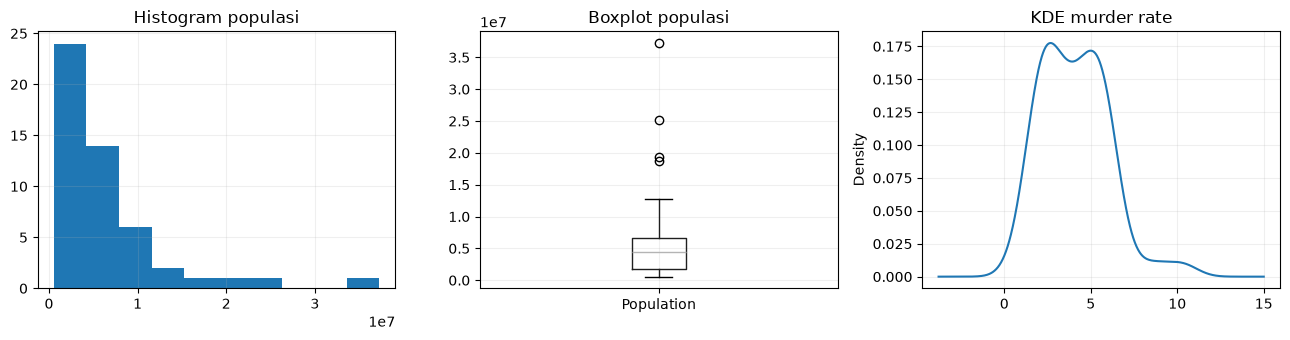

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
state['Population'].hist(bins=10, ax=axes[0]); axes[0].set_title('Histogram populasi')
state.boxplot(column='Population', ax=axes[1]); axes[1].set_title('Boxplot populasi')
state['Murder.Rate'].plot.kde(ax=axes[2]); axes[2].set_title('KDE murder rate')
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 5. Dua variabel sekaligus

Korelasi Pearson mengukur asosiasi **linear**, dengan nilai dari -1 sampai 1. Nilainya tidak menyatakan sebab-akibat, dan dapat dipengaruhi pencilan. Scatterplot perlu dibaca bersama koefisiennya. Categorical summary di bawah adalah pengelompokan analitis buatan notebook, **bukan** kategori asli dalam dataset.

Korelasi Pearson: 0.182
                  count  median  mean
population_group                     
Q1 kecil             13    2.40  2.78
Q2                   12    3.80  4.07
Q3                   12    5.35  4.98
Q4 besar             13    4.40  4.50


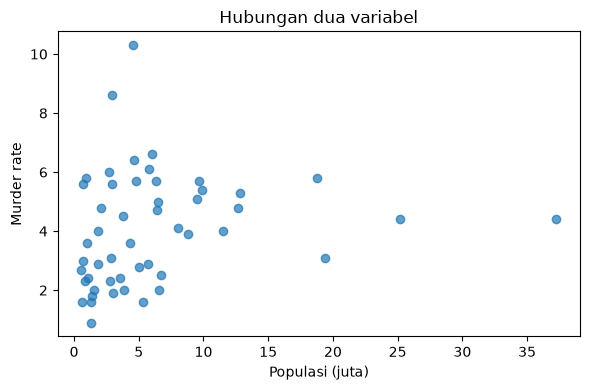

In [6]:
state['population_group'] = pd.qcut(state['Population'], q=4, labels=['Q1 kecil', 'Q2', 'Q3', 'Q4 besar'])
print('Korelasi Pearson:', round(state['Population'].corr(state['Murder.Rate']), 3))
print(state.groupby('population_group', observed=True)['Murder.Rate'].agg(['count', 'median', 'mean']).round(2))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(state['Population'] / 1e6, state['Murder.Rate'], alpha=.7)
ax.set(xlabel='Populasi (juta)', ylabel='Murder rate', title='Hubungan dua variabel')
plt.tight_layout(); plt.show()

### Ringkasan dan refleksi

- Pemilihan statistik harus mengikuti tipe data, unit analisis, dan pertanyaan riset.
- Mean/SD efisien untuk distribusi relatif simetris; median/IQR lebih tahan nilai ekstrem.
- Grafik adalah pemeriksaan terhadap ringkasan angka, bukan ornamen.
- Korelasi pada data observasional tidak membuktikan kausalitas. Data ini bersifat historis, sehingga tidak boleh ditafsirkan sebagai kondisi terkini.